JS04 Tugas 1 - K-Means pada Mall_Customers.csv.

Fitur dipilih: Age, Annual Income (k$), Spending Score (1-100).
Gender tidak dipakai sebagai fitur (kategorikal biner, tidak menambah struktur jarak).
k terbaik dicari dengan elbow (SSE) + silhouette score.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("tugas_kmeans.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js04-klasterisasi\tugas


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

DATA = Path(__file__).resolve().parents[1] / "data"
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA / "Mall_Customers.csv")
print(df.head(), "\n")

FITUR = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(df[FITUR])

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40 



k=1; SSE=600.0000; silhouette=nan
k=2; SSE=389.3862; silhouette=0.3355
k=3; SSE=295.2122; silhouette=0.3578
k=4; SSE=205.2251; silhouette=0.4040
k=5; SSE=168.2476; silhouette=0.4166
k=6; SSE=133.8684; silhouette=0.4284
k=7; SSE=117.0116; silhouette=0.4172
k=8; SSE=103.8733; silhouette=0.4082
k=9; SSE=93.0929; silhouette=0.4177
k=10; SSE=82.3852; silhouette=0.4066

k terbaik menurut silhouette: 6 (skor 0.4284)


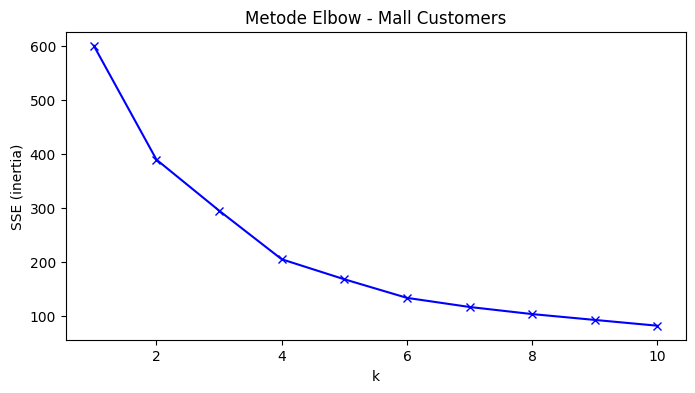

In [3]:
# Elbow + silhouette untuk k=1..10
inertia, sil = [], {}
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    if k > 1:
        sil[k] = silhouette_score(X, km.labels_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertia, "bx-")
plt.xlabel("k")
plt.ylabel("SSE (inertia)")
plt.title("Metode Elbow - Mall Customers")
plt.savefig(OUT / "01_elbow.png", dpi=120, bbox_inches="tight")

for k, v in enumerate(inertia, 1):
    print(f"k={k}; SSE={v:.4f}; silhouette={sil.get(k, float('nan')):.4f}")

k_best = max(sil, key=sil.get)
print(f"\nk terbaik menurut silhouette: {k_best} (skor {sil[k_best]:.4f})")


Ringkasan tiap cluster:
          Age  Annual Income (k$)  Spending Score (1-100)  Jumlah
Cluster                                                          
0        56.3                54.3                    49.1      45
1        26.8                57.1                    48.1      39
2        41.9                88.9                    17.0      33
3        32.7                86.5                    82.1      39
4        25.0                25.3                    77.6      23
5        45.5                26.3                    19.4      21

Gender per cluster:
Gender   Female  Male
Cluster              
0            26    19
1            25    14
2            14    19
3            21    18
4            13    10
5            13     8


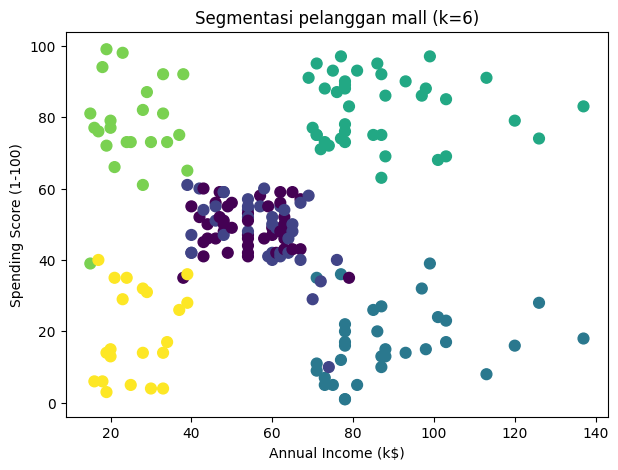

In [4]:
# Model final
km = KMeans(n_clusters=k_best, random_state=42, n_init=10)
df["Cluster"] = km.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"],
            c=df["Cluster"], cmap="viridis", s=60)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"Segmentasi pelanggan mall (k={k_best})")
plt.savefig(OUT / "02_hasil_cluster.png", dpi=120, bbox_inches="tight")

ringkasan = df.groupby("Cluster")[FITUR].mean().round(1)
ringkasan["Jumlah"] = df["Cluster"].value_counts().sort_index()
print("\nRingkasan tiap cluster:")
print(ringkasan)
print("\nGender per cluster:")
print(pd.crosstab(df["Cluster"], df["Gender"]))